In [1]:
import warnings
from sklearn.exceptions import InconsistentVersionWarning

warnings.filterwarnings(
    "ignore",
    category=InconsistentVersionWarning
)

from pathlib import Path
import pandas as pd
import numpy as np
import joblib

PROJECT_ROOT = Path(
    r"C:\Users\nijag\Multi-Modal-Phishing_Detector"
)

PROCESSED_EMAIL_DIR = PROJECT_ROOT / "data" / "processed" / "email"
MODEL_DIR = PROCESSED_EMAIL_DIR / "models"

print("Project folder exists:", PROJECT_ROOT.exists())
print("Models folder exists:", MODEL_DIR.exists())

Project folder exists: True
Models folder exists: True


In [2]:
from pathlib import Path

PROJECT_ROOT = Path(r"C:\Users\nijag\Multi-Modal-Phishing_Detector")

PROCESSED_EMAIL_DIR = (
    PROJECT_ROOT / "data" / "processed" / "email"
)

MODEL_DIR = PROCESSED_EMAIL_DIR / "models"

print("Processed email directory:", PROCESSED_EMAIL_DIR)
print("Directory exists:", PROCESSED_EMAIL_DIR.exists())

Processed email directory: C:\Users\nijag\Multi-Modal-Phishing_Detector\data\processed\email
Directory exists: True


In [3]:
# Load trained models
scaler = joblib.load(
    MODEL_DIR / "numerical_scaler_final.joblib"
)
lr_model = joblib.load(MODEL_DIR / "logistic_regression_final.joblib")
rf_model = joblib.load(MODEL_DIR / "random_forest_final.joblib")
xgb_model = joblib.load(MODEL_DIR / "xgboost_final.joblib")

# Load preprocessing components
tfidf_vectorizer = joblib.load(MODEL_DIR / "tfidf_vectorizer_final.joblib")
scaler = joblib.load(MODEL_DIR / "numerical_scaler_final.joblib")

numerical_feature_names = joblib.load(
    MODEL_DIR / "numerical_feature_names_final.joblib"
)

print("All models and preprocessing components loaded successfully!")

print("\nTF-IDF features:", len(tfidf_vectorizer.get_feature_names_out()))
print("Numerical features:", numerical_feature_names)
print("Logistic Regression coefficients:", lr_model.coef_.shape)

C:\anaconda3\envs\phishing-email\Lib\pickle.py:1718: UserWarning: [16:26:26] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\gbm\../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)


All models and preprocessing components loaded successfully!

TF-IDF features: 20000
Numerical features: ['text_length', 'word_count', 'url_count', 'urgency_count', 'threat_count', 'financial_count']
Logistic Regression coefficients: (1, 20006)


In [54]:
# Load trained models
scaler = joblib.load(
    MODEL_DIR / "numerical_scaler_final.joblib"
)
lr_model = joblib.load(MODEL_DIR / "logistic_regression_final.joblib")
rf_model = joblib.load(MODEL_DIR / "random_forest_final.joblib")
xgb_model = joblib.load(MODEL_DIR / "xgboost_final.joblib")

# Load preprocessing components
tfidf_vectorizer = joblib.load(MODEL_DIR / "tfidf_vectorizer_final.joblib")
scaler = joblib.load(MODEL_DIR / "numerical_scaler_final.joblib")

numerical_feature_names = joblib.load(
    MODEL_DIR / "numerical_feature_names_final.joblib"
)

print("All models and preprocessing components loaded successfully!")

print("\nTF-IDF features:", len(tfidf_vectorizer.get_feature_names_out()))
print("Numerical features:", numerical_feature_names)
print("Logistic Regression coefficients:", lr_model.coef_.shape)

All models and preprocessing components loaded successfully!

TF-IDF features: 20000
Numerical features: ['text_length', 'word_count', 'url_count', 'urgency_count', 'threat_count', 'financial_count']
Logistic Regression coefficients: (1, 20006)


In [4]:
print("Model:", lr_model)
print("Number of model coefficients:", len(lr_model.coef_[0]))
print("Number of TF-IDF features:", len(tfidf_vectorizer.get_feature_names_out()))
print("Number of numerical features:", len(numerical_feature_names))

print("\nModel verification completed!")

Model: LogisticRegression(max_iter=3000, random_state=42)
Number of model coefficients: 20006
Number of TF-IDF features: 20000
Number of numerical features: 6

Model verification completed!


In [5]:
import joblib
from pathlib import Path

PROJECT_ROOT = Path(r"C:\Users\nijag\Multi-Modal-Phishing_Detector")

MODEL_DIR = PROJECT_ROOT / "data" / "processed" / "email" / "models"

numerical_feature_names = joblib.load(
    MODEL_DIR / "numerical_feature_names_final.joblib"
)

print("Numerical feature names:", numerical_feature_names)

Numerical feature names: ['text_length', 'word_count', 'url_count', 'urgency_count', 'threat_count', 'financial_count']


In [6]:
EXTERNAL_DIR = PROJECT_ROOT / "data" / "external"

print("External folder exists:", EXTERNAL_DIR.exists())

print("\nFiles and folders:")
for item in EXTERNAL_DIR.rglob("*"):
    print(item)

External folder exists: True

Files and folders:
C:\Users\nijag\Multi-Modal-Phishing_Detector\data\external\Phishing_validation_emails_v2.csv


In [7]:
import pandas as pd

external_file = EXTERNAL_DIR / "Phishing_validation_emails_v2.csv"

external_df = pd.read_csv(external_file)

print("Dataset shape:", external_df.shape)

print("\nColumn names:")
print(external_df.columns.tolist())

print("\nFirst 5 records:")
display(external_df.head())

print("\nMissing values:")
print(external_df.isnull().sum())

Dataset shape: (2000, 2)

Column names:
['Email Text', 'Email Type']

First 5 records:


,Email Text,Email Type
0,"Dmitri, Action required: confirm your direct-d...",Phishing Email
1,"Hi Riley, Thanks for signing up for our webina...",Safe Email
2,"Hi there Dana, We detected an unusual sign-in ...",Phishing Email
3,"Hi there Pat, You are eligible for a tax refun...",Phishing Email
4,"Jordan, Omar has shared a document with you on...",Phishing Email



Missing values:
Email Text    0
Email Type    0
dtype: int64


In [8]:
print("Email class distribution:")
print(external_df["Email Type"].value_counts())

print("\nClass percentages:")
print(
    external_df["Email Type"].value_counts(normalize=True) * 100
)

# Check duplicate emails
print(
    "\nExact duplicate emails:",
    external_df["Email Text"].duplicated().sum()
)

# Check unique emails after normalisation
normalized_emails = (
    external_df["Email Text"]
    .astype(str)
    .str.lower()
    .str.strip()
)

print(
    "Duplicates after basic normalization:",
    normalized_emails.duplicated().sum()
)

Email class distribution:
Email Type
Phishing Email    1000
Safe Email        1000
Name: count, dtype: int64

Class percentages:
Email Type
Phishing Email    50.0
Safe Email        50.0
Name: proportion, dtype: float64

Exact duplicate emails: 0
Duplicates after basic normalization: 0


In [9]:
import re

# Load the cleaned training dataset
TRAIN_FILE = PROCESSED_EMAIL_DIR / "email_cleaned.csv"

training_df = pd.read_csv(TRAIN_FILE)

def normalize_email(text):
    text = str(text).lower().strip()
    text = re.sub(r"\s+", " ", text)
    return text

training_emails = set(
    training_df["email_text"].dropna().apply(normalize_email)
)

external_emails = external_df["Email Text"].fillna("").apply(normalize_email)

overlap = external_emails.isin(training_emails)

print("External emails:", len(external_df))
print("Emails overlapping with training data:", overlap.sum())
print("Independent external emails:", (~overlap).sum())

External emails: 2000
Emails overlapping with training data: 0
Independent external emails: 2000


In [10]:
# Convert email categories into numerical labels
label_mapping = {
    "Safe Email": 0,
    "Phishing Email": 1
}

external_df["label"] = external_df["Email Type"].map(label_mapping)

# Prepare email text and actual labels
X_external_text = external_df["Email Text"].fillna("").astype(str)
y_external = external_df["label"]

print("External dataset prepared!")

print("\nLabel distribution:")
print(y_external.value_counts().sort_index())

print("\nLabel mapping:")
print("0 = Legitimate")
print("1 = Spam/Malicious")

print("\nTotal emails:", len(X_external_text))
print("Missing labels:", y_external.isnull().sum())

External dataset prepared!

Label distribution:
label
0    1000
1    1000
Name: count, dtype: int64

Label mapping:
0 = Legitimate
1 = Spam/Malicious

Total emails: 2000
Missing labels: 0


In [11]:
import re
import pandas as pd

# Define the same keyword lists used during model training
urgency_words = [
    "urgent", "immediately", "now", "hurry",
    "expires", "limited time", "act now"
]

threat_words = [
    "suspended", "blocked", "terminated",
    "locked", "deactivated", "unauthorized"
]

financial_words = [
    "bank", "payment", "account", "invoice",
    "refund", "credit card", "transaction", "money"
]

# Extract numerical features
def extract_numerical_features(text):
    text = str(text).lower()

    return {
        "text_length": len(text),
        "word_count": len(text.split()),
        "url_count": len(re.findall(r"https?://\S+|www\.\S+", text)),
        "urgency_count": sum(
            len(re.findall(r"\b" + re.escape(word) + r"\b", text))
            for word in urgency_words
        ),
        "threat_count": sum(
            len(re.findall(r"\b" + re.escape(word) + r"\b", text))
            for word in threat_words
        ),
        "financial_count": sum(
            len(re.findall(r"\b" + re.escape(word) + r"\b", text))
            for word in financial_words
        )
    }

# Apply feature extraction to all 2,000 external emails
external_num_df = pd.DataFrame(
    [extract_numerical_features(email) for email in X_external_text]
)

# Maintain exactly the same feature order used during training
external_num_df = external_num_df[numerical_feature_names]

print("Numerical feature extraction completed!")
print("\nFeature names:", external_num_df.columns.tolist())
print("Feature matrix shape:", external_num_df.shape)

display(external_num_df.head())

Numerical feature extraction completed!

Feature names: ['text_length', 'word_count', 'url_count', 'urgency_count', 'threat_count', 'financial_count']
Feature matrix shape: (2000, 6)


,text_length,word_count,url_count,urgency_count,threat_count,financial_count
0,192,24,1,0,0,0
1,151,27,0,0,0,0
2,218,33,1,0,1,3
3,178,27,1,0,0,1
4,185,26,1,0,0,0


In [12]:
external_num_scaled = scaler.transform(external_num_df)

print("External numerical features scaled successfully!")
print("Scaled feature matrix shape:", external_num_scaled.shape)
print("\nFirst 5 scaled records:")
print(external_num_scaled[:5])

External numerical features scaled successfully!
Scaled feature matrix shape: (2000, 6)

First 5 scaled records:
[[4.17419072e-05 1.88787590e-04 3.19081047e-04 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [3.28282708e-05 2.12386039e-04 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [4.73944571e-05 2.59582937e-04 3.19081047e-04 0.00000000e+00
  1.75438596e-02 3.22234157e-03]
 [3.86982264e-05 2.12386039e-04 3.19081047e-04 0.00000000e+00
  0.00000000e+00 1.07411386e-03]
 [4.02200668e-05 2.04519890e-04 3.19081047e-04 0.00000000e+00
  0.00000000e+00 0.00000000e+00]]


In [13]:
print("TF-IDF vectorizer loaded successfully!")
print(
    "Number of TF-IDF features:",
    len(tfidf_vectorizer.get_feature_names_out())
)

TF-IDF vectorizer loaded successfully!
Number of TF-IDF features: 20000


In [14]:
external_tfidf = tfidf_vectorizer.transform(X_external_text)

print("External TF-IDF transformation completed!")
print("TF-IDF matrix shape:", external_tfidf.shape)

External TF-IDF transformation completed!
TF-IDF matrix shape: (2000, 20000)


In [15]:
from scipy.sparse import hstack, csr_matrix

# Convert scaled numerical features into a sparse matrix
external_num_sparse = csr_matrix(external_num_scaled)

# Combine TF-IDF and numerical features
X_external_combined = hstack(
    [external_tfidf, external_num_sparse],
    format="csr"
)

print("External feature combination completed!")
print("Final external matrix shape:", X_external_combined.shape)
print("Total features:", X_external_combined.shape[1])

External feature combination completed!
Final external matrix shape: (2000, 20006)
Total features: 20006


In [55]:
# Generate predictions using all three trained models

y_pred_lr_external = lr_model.predict(X_external_combined)

y_pred_rf_external = rf_model.predict(X_external_combined)

y_pred_xgb_external = xgb_model.predict(X_external_combined)

print("External predictions completed!")

print("\nTotal emails tested:", len(y_external))

print("\nPrediction counts:")

print("\nLogistic Regression:")
print(pd.Series(y_pred_lr_external).value_counts().sort_index())

print("\nRandom Forest:")
print(pd.Series(y_pred_rf_external).value_counts().sort_index())

print("\nXGBoost:")
print(pd.Series(y_pred_xgb_external).value_counts().sort_index())

External predictions completed!

Total emails tested: 2000

Prediction counts:

Logistic Regression:
0     834
1    1166
Name: count, dtype: int64

Random Forest:
0     240
1    1760
Name: count, dtype: int64

XGBoost:
0     482
1    1518
Name: count, dtype: int64


In [56]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

external_predictions = {
    "Logistic Regression": y_pred_lr_external,
    "Random Forest": y_pred_rf_external,
    "XGBoost": y_pred_xgb_external
}

external_results = []

for name, predictions in external_predictions.items():

    accuracy = accuracy_score(y_external, predictions) * 100
    precision = precision_score(y_external, predictions) * 100
    recall = recall_score(y_external, predictions) * 100
    f1 = f1_score(y_external, predictions) * 100

    external_results.append({
        "Model": name,
        "Accuracy (%)": accuracy,
        "Precision (%)": precision,
        "Recall (%)": recall,
        "F1-Score (%)": f1
    })

    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    print(f"Accuracy:  {accuracy:.2f}%")
    print(f"Precision: {precision:.2f}%")
    print(f"Recall:    {recall:.2f}%")
    print(f"F1-Score:  {f1:.2f}%")

    print("\nClassification Report:")
    print(
        classification_report(
            y_external,
            predictions,
            target_names=["Legitimate", "Spam/Malicious"],
            digits=4
        )
    )

    print("Confusion Matrix:")
    print(confusion_matrix(y_external, predictions))


external_results_df = pd.DataFrame(external_results)

print("\nFINAL EXTERNAL MODEL COMPARISON (%)")
display(external_results_df.round(2))


Logistic Regression
Accuracy:  90.50%
Precision: 84.73%
Recall:    98.80%
F1-Score:  91.23%

Classification Report:
                precision    recall  f1-score   support

    Legitimate     0.9856    0.8220    0.8964      1000
Spam/Malicious     0.8473    0.9880    0.9123      1000

      accuracy                         0.9050      2000
     macro avg     0.9165    0.9050    0.9043      2000
  weighted avg     0.9165    0.9050    0.9043      2000

Confusion Matrix:
[[822 178]
 [ 12 988]]

Random Forest
Accuracy:  61.90%
Precision: 56.76%
Recall:    99.90%
F1-Score:  72.39%

Classification Report:
                precision    recall  f1-score   support

    Legitimate     0.9958    0.2390    0.3855      1000
Spam/Malicious     0.5676    0.9990    0.7239      1000

      accuracy                         0.6190      2000
     macro avg     0.7817    0.6190    0.5547      2000
  weighted avg     0.7817    0.6190    0.5547      2000

Confusion Matrix:
[[239 761]
 [  1 999]]

XGBoost
Acc

,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,Logistic Regression,90.5,84.73,98.8,91.23
1,Random Forest,61.9,56.76,99.9,72.39
2,XGBoost,72.7,64.95,98.6,78.32


In [18]:
# Create a copy of the external dataset for error analysis
error_analysis_df = external_df.copy()

# Add actual and predicted labels
error_analysis_df["Actual_Label"] = y_external.values
error_analysis_df["Predicted_Label"] = y_pred_lr_external

# Identify types of incorrect predictions
error_analysis_df["Error_Type"] = error_analysis_df.apply(
    lambda row:
        "False Positive"
        if row["Actual_Label"] == 0 and row["Predicted_Label"] == 1
        else "False Negative"
        if row["Actual_Label"] == 1 and row["Predicted_Label"] == 0
        else "Correct",
    axis=1
)

# Separate the two types of errors
false_positives = error_analysis_df[
    error_analysis_df["Error_Type"] == "False Positive"
]

false_negatives = error_analysis_df[
    error_analysis_df["Error_Type"] == "False Negative"
]

print("ERROR ANALYSIS - LOGISTIC REGRESSION")
print("=" * 50)

print("False Positives:", len(false_positives))
print("False Negatives:", len(false_negatives))
print("Total Misclassified:", len(false_positives) + len(false_negatives))

print("\nFIRST 5 FALSE POSITIVES:")
display(
    false_positives[["Email Type", "Email Text"]].head(5)
)

print("\nFIRST 5 FALSE NEGATIVES:")
display(
    false_negatives[["Email Type", "Email Text"]].head(5)
)

ERROR ANALYSIS - LOGISTIC REGRESSION
False Positives: 178
False Negatives: 12
Total Misclassified: 190

FIRST 5 FALSE POSITIVES:


,Email Type,Email Text
13,Safe Email,Dear Victor Thank you for your purchase. Your ...
23,Safe Email,"Hi Ivan, Your subscription to Greenleaf Ltd st..."
28,Safe Email,"Good day Dana, A quick heads-up: IT will perfo..."
37,Safe Email,Dear Pat Your order ORD87150 from MetroUtiliti...
44,Safe Email,"Jamie, Thank you for your purchase. Your loyal..."



FIRST 5 FALSE NEGATIVES:


,Email Type,Email Text
439,Phishing Email,"Good day Elliot, Marco here. I need you to pur..."
520,Phishing Email,"Hi there Avery, You have a new secure message ..."
1004,Phishing Email,"Hi Chris, Avery has shared a document with you..."
1008,Phishing Email,"Clara, You have a new secure message from Mail..."
1205,Phishing Email,"Sam, Jesse has shared a document with you on H..."


In [19]:
import numpy as np

# Get all feature names
feature_names = (
    list(tfidf_vectorizer.get_feature_names_out())
    + list(numerical_feature_names)
)

# Get Logistic Regression coefficients
model_coefficients = lr_model.coef_[0]

def inspect_prediction(email_indices, error_type, direction):

    print("\n" + "=" * 60)
    print(error_type)
    print("=" * 60)

    for idx in email_indices[:3]:

        idx = error_analysis_df.index.get_loc(idx)

        # Get feature values for this email
        email_features = X_external_combined.getrow(idx)

        # Calculate individual feature contributions
        contributions = np.asarray(
            email_features.multiply(model_coefficients).toarray()
        ).ravel()

        # Select features pushing towards the relevant class
        if direction == "malicious":
            selected_indices = np.where(contributions > 0)[0]
            selected_indices = selected_indices[
                np.argsort(contributions[selected_indices])[::-1]
            ]
        else:
            selected_indices = np.where(contributions < 0)[0]
            selected_indices = selected_indices[
                np.argsort(contributions[selected_indices])
            ]

        print(f"\nEmail index: {idx}")
        print("Email text:")
        print(external_df.iloc[idx]["Email Text"][:300])

        print("\nTop contributing features:")

        for feature_idx in selected_indices[:8]:
            print(
                f"{feature_names[feature_idx]} : "
                f"{contributions[feature_idx]:.4f}"
            )


# Inspect false positives
inspect_prediction(
    false_positives.index,
    "FALSE POSITIVES - Features pushing towards malicious",
    "malicious"
)

# Inspect false negatives
inspect_prediction(
    false_negatives.index,
    "FALSE NEGATIVES - Features pushing towards legitimate",
    "legitimate"
)


FALSE POSITIVES - Features pushing towards malicious

Email index: 13
Email text:
Dear Victor Thank you for your purchase. Your cloud backup with StreamGo has been activated and a receipt for $49.99 is attached for your records. Best regards, Clara

Top contributing features:
your : 1.5518
you : 0.3813
best : 0.3813
dear : 0.3244
cloud : 0.2431
99 : 0.0894
been : 0.0327
records : 0.0247

Email index: 23
Email text:
Hi Ivan, Your subscription to Greenleaf Ltd storage upgrade renews on March 4. No action is needed; this note is just to confirm the upcoming charge of $19.95. Best, Clara

Top contributing features:
your : 0.6338
95 : 0.3543
best : 0.3268
no : 0.2975
confirm : 0.1683
upgrade : 0.1401
charge : 0.0985
ltd : 0.0928

Email index: 28
Email text:
Good day Dana, A quick heads-up: IT will perform scheduled maintenance on the internal wiki this Tuesday evening. No action is required from you. Best, Tomas

Top contributing features:
good day : 0.3897
you : 0.3421
best : 0.3421
no : 

In [20]:
# Select one email from the external dataset
email_index = 13

# Get the email features
sample_email = X_external_combined[email_index]

# Get its actual label
actual_label = y_external.iloc[email_index]

label_names = {
    0: "Legitimate",
    1: "Spam / Malicious"
}

# Compare all three models
models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

print("=" * 65)
print("EMAIL PHISHING DETECTION - MODEL COMPARISON")
print("=" * 65)

print("\nEMAIL:")
print(external_df.iloc[email_index]["Email Text"])

print("\nActual Category:", label_names[actual_label])

print("\nMODEL PREDICTIONS:")
print("-" * 65)

for model_name, model in models.items():

    prediction = model.predict(sample_email)[0]

    probabilities = model.predict_proba(sample_email)[0]

    malicious_probability = probabilities[
        list(model.classes_).index(1)
    ]

    print(f"\nModel: {model_name}")
    print("Predicted Category:", label_names[prediction])
    print(
        "Malicious Probability:",
        f"{malicious_probability * 100:.2f}%"
    )

EMAIL PHISHING DETECTION - MODEL COMPARISON

EMAIL:
Dear Victor Thank you for your purchase. Your cloud backup with StreamGo has been activated and a receipt for $49.99 is attached for your records. Best regards, Clara

Actual Category: Legitimate

MODEL PREDICTIONS:
-----------------------------------------------------------------

Model: Logistic Regression
Predicted Category: Spam / Malicious
Malicious Probability: 75.18%

Model: Random Forest
Predicted Category: Spam / Malicious
Malicious Probability: 66.38%

Model: XGBoost
Predicted Category: Spam / Malicious
Malicious Probability: 68.51%


In [21]:

# Enter a new email for prediction
# Paste both the subject and email body together.

new_email = """
Subject: Reminder: Project Review Meeting

Dear Team,

This is a reminder that our project review meeting
will be held tomorrow at 11:00 AM in the seminar hall.

Please bring your updated project reports and
be prepared to discuss your progress.

Thank you for your cooperation.

Best regards,
Project Coordinator
"""

print("Email entered successfully!")
print(new_email)


Email entered successfully!

Subject: Reminder: Project Review Meeting

Dear Team,

This is a reminder that our project review meeting
will be held tomorrow at 11:00 AM in the seminar hall.

Please bring your updated project reports and
be prepared to discuss your progress.

Thank you for your cooperation.

Best regards,
Project Coordinator



In [22]:

import pandas as pd
from scipy.sparse import hstack, csr_matrix

if not new_email.strip():
    raise ValueError("Please enter an email before prediction.")

# 1. Extract numerical features
new_email_num = pd.DataFrame(
    [extract_numerical_features(new_email)],
    columns=numerical_feature_names
)

# 2. Scale numerical features using the saved scaler
new_email_num_scaled = scaler.transform(new_email_num)

# 3. Convert email text into TF-IDF features
new_email_tfidf = tfidf_vectorizer.transform([new_email])

# 4. Combine TF-IDF and numerical features
new_email_features = hstack(
    [new_email_tfidf, csr_matrix(new_email_num_scaled)],
    format="csr"
)

# 5. Predict using all three trained models
models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

label_names = {
    0: "Legitimate Email",
    1: "Spam / Malicious Email"
}

print("========== EMAIL PREDICTION RESULTS ==========")

for name, model in models.items():
    prediction = int(model.predict(new_email_features)[0])

    probabilities = model.predict_proba(new_email_features)[0]
    malicious_probability = probabilities[
        list(model.classes_).index(1)
    ] * 100

    print("\nModel:", name)
    print("Prediction:", label_names[prediction])
    print(f"Malicious Probability: {malicious_probability:.2f}%")

print("\n==============================================")


========== EMAIL PREDICTION RESULTS ==========

Model: Logistic Regression
Prediction: Legitimate Email
Malicious Probability: 4.53%

Model: Random Forest
Prediction: Legitimate Email
Malicious Probability: 40.42%

Model: XGBoost
Prediction: Spam / Malicious Email
Malicious Probability: 75.29%



In [23]:
import warnings

warnings.filterwarnings(
    "ignore",
    message="IProgress not found.*",
    category=Warning
)

import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.51.0


In [24]:
import warnings
from sklearn.exceptions import InconsistentVersionWarning

warnings.filterwarnings(
    "ignore",
    category=InconsistentVersionWarning
)


print("Known model-loading warnings suppressed.")

Known model-loading warnings suppressed.


In [25]:
print("Logistic Regression:", type(lr_model).__name__)
print("Random Forest:", type(rf_model).__name__)
print("XGBoost:", type(xgb_model).__name__)

print("\nTF-IDF features:",
      len(tfidf_vectorizer.get_feature_names_out()))

print("Numerical features:", len(numerical_feature_names))
print("Total model features:", lr_model.coef_.shape[1])

Logistic Regression: LogisticRegression
Random Forest: RandomForestClassifier
XGBoost: XGBClassifier

TF-IDF features: 20000
Numerical features: 6
Total model features: 20006


In [26]:
FEATURE_DIR = PROCESSED_EMAIL_DIR / "features"

print("Feature folder exists:", FEATURE_DIR.exists())

for file in FEATURE_DIR.iterdir():
    print(file.name)

Feature folder exists: True
numerical_feature_names.joblib
tfidf_vectorizer.joblib
X_test_features.npz
X_train_features.npz
y_test.csv
y_train.csv


In [27]:
PROCESSED_DIR = PROCESSED_EMAIL_DIR

for file in PROCESSED_DIR.rglob("*"):
    if file.is_file():
        print(file.relative_to(PROCESSED_DIR))

combined_duplicate_summary.csv
dataset_initial_summary.csv
duplicate_summary_before_cleaning.csv
email_cleaned.csv
email_combined_before_cleaning.csv
email_model_comparison.csv
label_and_duplicate_summary.csv
features\numerical_feature_names.joblib
features\tfidf_vectorizer.joblib
features\X_test_features.npz
features\X_train_features.npz
features\y_test.csv
features\y_train.csv
models\logistic_regression_final.joblib
models\numerical_feature_names_final.joblib
models\numerical_scaler_final.joblib
models\random_forest_final.joblib
models\tfidf_vectorizer_final.joblib
models\xgboost_final.joblib
standardized\CEAS_08_standardized.csv
standardized\Enron_standardized.csv
standardized\Ling_standardized.csv
standardized\Nazario_standardized.csv
standardized\Nigerian_Fraud_standardized.csv
standardized\phishing_email_standardized.csv
standardized\SpamAssasin_standardized.csv


In [28]:
email_df = pd.read_csv(PROCESSED_DIR / "email_cleaned.csv")

print("Dataset shape:", email_df.shape)

print("\nLabel distribution:")
print(email_df["label"].value_counts())

print("\nDuplicate email texts:",
      email_df["email_text"].duplicated().sum())

Dataset shape: (164563, 10)

Label distribution:
label
1    85735
0    78828
Name: count, dtype: int64

Duplicate email texts: 64


In [29]:
email_df_deduplicated = email_df.copy()

print("Dataset records:", len(email_df_deduplicated))
print("Duplicate email texts:",
      email_df_deduplicated["email_text"].duplicated().sum())

print("\nLabel distribution:")
print(email_df_deduplicated["label"].value_counts())

Dataset records: 164563
Duplicate email texts: 64

Label distribution:
label
1    85735
0    78828
Name: count, dtype: int64


In [30]:
from sklearn.model_selection import train_test_split

X_train_text, X_test_text, y_train, y_test = train_test_split(
    email_df_deduplicated["email_text"],
    email_df_deduplicated["label"],
    test_size=0.2,
    random_state=42,
    stratify=email_df_deduplicated["label"]
)

print("Training samples:", len(X_train_text))
print("Testing samples:", len(X_test_text))

Training samples: 131650
Testing samples: 32913


In [31]:
print("Numerical feature extraction function available:",
      callable(extract_numerical_features))

print("Feature names:", numerical_feature_names)

Numerical feature extraction function available: True
Feature names: ['text_length', 'word_count', 'url_count', 'urgency_count', 'threat_count', 'financial_count']


In [32]:
train_num_df = pd.DataFrame(
    [extract_numerical_features(text) for text in X_train_text],
    columns=numerical_feature_names
)

train_num_scaled = scaler.transform(train_num_df)

train_tfidf = tfidf_vectorizer.transform(X_train_text)

X_train_combined = hstack(
    [train_tfidf, csr_matrix(train_num_scaled)],
    format="csr"
)

print("Final training matrix:", X_train_combined.shape)
print("Expected model features:", lr_model.coef_.shape[1])

Final training matrix: (131650, 20006)
Expected model features: 20006


In [33]:
train_predictions = lr_model.predict(X_train_combined)

print("Training predictions generated:", len(train_predictions))
print("Prediction distribution:")
print(pd.Series(train_predictions).value_counts().sort_index())

print("\nTraining accuracy on reconstructed data:",
      round(lr_model.score(X_train_combined, y_train), 4))

Training predictions generated: 131650
Prediction distribution:
0    62859
1    68791
Name: count, dtype: int64

Training accuracy on reconstructed data: 0.9916


In [34]:
import re
from sklearn.model_selection import train_test_split
from scipy.sparse import hstack, csr_matrix

# Load cleaned dataset
training_df = pd.read_csv(
    PROCESSED_EMAIL_DIR / "email_cleaned.csv"
)

training_df = training_df.drop_duplicates(
    subset=["email_text"]
).reset_index(drop=True)

X = training_df["email_text"].fillna("")
y = training_df["label"]

# Recreate the original train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Numerical feature extraction
urgency_words = [
    "urgent", "immediately", "now", "hurry",
    "expires", "limited time", "act now"
]

threat_words = [
    "suspended", "blocked", "terminated",
    "locked", "deactivated", "unauthorized"
]

financial_words = [
    "bank", "payment", "account", "invoice",
    "refund", "credit card", "transaction", "money"
]

def extract_numerical_features(text):
    text = str(text).lower()

    return {
        "text_length": len(text),
        "word_count": len(text.split()),
        "url_count": len(re.findall(r"https?://\S+|www\.\S+", text)),
        "urgency_count": sum(
            len(re.findall(r"\b" + re.escape(word) + r"\b", text))
            for word in urgency_words
        ),
        "threat_count": sum(
            len(re.findall(r"\b" + re.escape(word) + r"\b", text))
            for word in threat_words
        ),
        "financial_count": sum(
            len(re.findall(r"\b" + re.escape(word) + r"\b", text))
            for word in financial_words
        )
    }

train_numerical = pd.DataFrame(
    [extract_numerical_features(text) for text in X_train],
    columns=numerical_feature_names
)

# Transform using the already-fitted preprocessing components
X_train_tfidf = tfidf_vectorizer.transform(X_train)

train_num_scaled = scaler.transform(train_numerical)
train_num_sparse = csr_matrix(train_num_scaled)

X_train_scaled = hstack(
    [X_train_tfidf, train_num_sparse],
    format="csr"
)

print("Training feature matrix:", X_train_scaled.shape)
print("Training labels:", y_train.shape)

Training feature matrix: (131599, 20006)
Training labels: (131599,)


In [35]:
# Reconstruct testing features

test_numerical = pd.DataFrame(
    [extract_numerical_features(text) for text in X_test],
    columns=numerical_feature_names
)

X_test_tfidf = tfidf_vectorizer.transform(X_test)

test_num_scaled = scaler.transform(test_numerical)

X_test_scaled = hstack(
    [X_test_tfidf, csr_matrix(test_num_scaled)],
    format="csr"
)

print("Testing feature matrix:", X_test_scaled.shape)
print("Testing labels:", y_test.shape)

Testing feature matrix: (32900, 20006)
Testing labels: (32900,)


In [36]:
# Select 100 representative training emails
background_data = X_train_scaled[:100]

# Create SHAP explainer
explainer = shap.LinearExplainer(
    lr_model,
    background_data
)

print("SHAP Linear Explainer created successfully!")
print("Background data shape:", background_data.shape)
print("Model coefficient shape:", lr_model.coef_.shape)

SHAP Linear Explainer created successfully!
Background data shape: (100, 20006)
Model coefficient shape: (1, 20006)


In [37]:
# Select one email from the test dataset
X_explain = X_test_scaled[0:1]

# Calculate SHAP values
shap_values = explainer.shap_values(X_explain)

print("SHAP values calculated successfully!")
print("SHAP values shape:", shap_values.shape)

SHAP values calculated successfully!
SHAP values shape: (1, 20006)


In [38]:
email_index = 0

print("Selected test email:")
print(X_test.iloc[email_index])

print("\nActual label:",
      y_test.iloc[email_index])

Selected test email:
Re: How can i  exclude a user or a host from smtpd_sender_restrictions? On 2/13/2008, AlxFrag (tizablg@gmail.com) wrote:
> In main.cf i have: 

Please provide full postcinf -n output, not manual snips from main.cf...

-- 

Best regards,

Charles

Actual label: 0


In [39]:
# Predict the selected email using Logistic Regression
prediction = lr_model.predict(X_explain)[0]

probability = lr_model.predict_proba(X_explain)[0]

print("Actual label:", y_test.iloc[email_index])
print("Predicted label:", prediction)

print("\nPrediction probabilities:")
print("Legitimate:", probability[0] * 100, "%")
print("Phishing:", probability[1] * 100, "%")

Actual label: 0
Predicted label: 0

Prediction probabilities:
Legitimate: 92.54662185264615 %
Phishing: 7.453378147353846 %


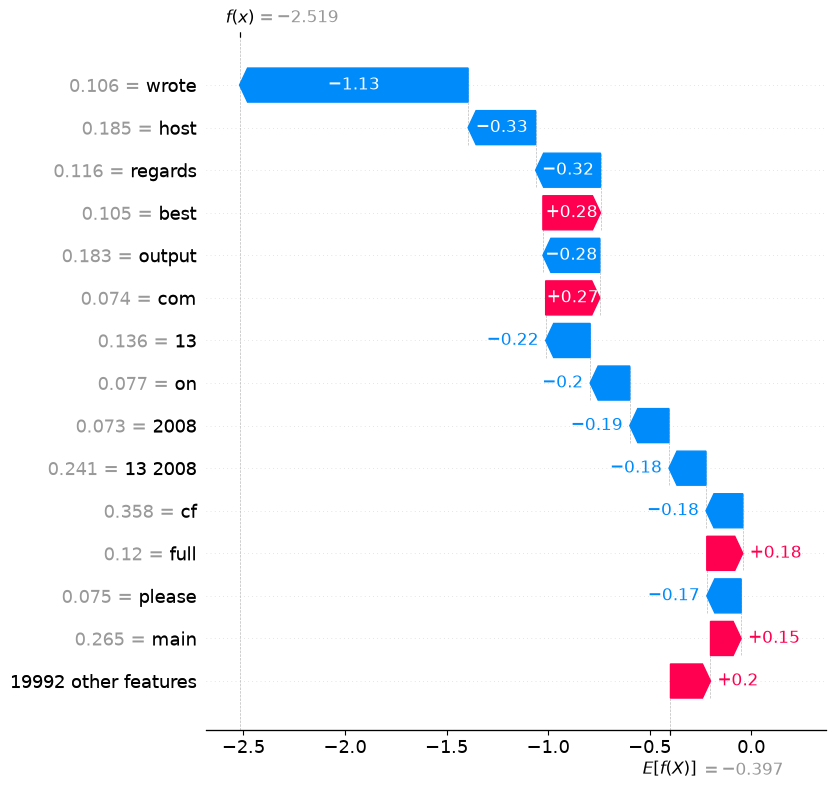

In [57]:

# Create meaningful feature names
feature_names = (
    tfidf_vectorizer.get_feature_names_out().tolist()
    + numerical_feature_names
)

# Generate SHAP explanation with feature names
shap_explanation = explainer(X_explain)

shap_explanation.feature_names = feature_names

# Display waterfall plot
shap.plots.waterfall(
    shap_explanation[0],
    max_display=15
)


In [41]:
import numpy as np

# Calculate SHAP values for the selected email
shap_values = explainer.shap_values(X_explain)

# Get feature names
feature_names = (
    tfidf_vectorizer.get_feature_names_out().tolist()
    + numerical_feature_names
)

email_shap_values = np.array(shap_values).reshape(-1)

# Find 15 features with highest absolute SHAP values
top_indices = np.argsort(
    np.abs(email_shap_values)
)[-15:][::-1]

top_features = pd.DataFrame({
    "Feature": [feature_names[i] for i in top_indices],
    "SHAP Value": [email_shap_values[i] for i in top_indices]
})

print("TOP 15 FEATURES INFLUENCING THE EMAIL PREDICTION")
display(top_features)

TOP 15 FEATURES INFLUENCING THE EMAIL PREDICTION


,Feature,SHAP Value
0,wrote,-1.125206
1,host,-0.332548
2,regards,-0.319554
3,best,0.283747
4,output,-0.280212
5,com,0.266581
6,13,-0.218987
7,on,-0.195149
8,2008,-0.192978
9,13 2008,-0.182210


In [42]:
email_index = 0

explained_email = X_test.iloc[email_index]

print("EMAIL BEING EXPLAINED")
print("=" * 60)
print(explained_email)

prediction = lr_model.predict(X_explain)[0]
probability = lr_model.predict_proba(X_explain)[0]

print("\nMODEL PREDICTION:",
      "Spam / Malicious" if prediction == 1 else "Legitimate")

print("Malicious probability:",
      round(probability[1] * 100, 2), "%")

print("Actual label:", y_test.iloc[email_index])

EMAIL BEING EXPLAINED
Re: How can i  exclude a user or a host from smtpd_sender_restrictions? On 2/13/2008, AlxFrag (tizablg@gmail.com) wrote:
> In main.cf i have: 

Please provide full postcinf -n output, not manual snips from main.cf...

-- 

Best regards,

Charles

MODEL PREDICTION: Legitimate
Malicious probability: 7.45 %
Actual label: 0


In [43]:
# Select one email whose actual label is 1 (Spam/Malicious)
phishing_email_text = X_train[y_train == 1].iloc[0]

# Extract numerical features
phishing_num_df = pd.DataFrame(
    [extract_numerical_features(phishing_email_text)],
    columns=numerical_feature_names
)

# Apply the already-fitted scaler and TF-IDF vectorizer
phishing_num_scaled = scaler.transform(phishing_num_df)
phishing_tfidf = tfidf_vectorizer.transform([phishing_email_text])

# Combine both feature sets
X_phishing_explain = hstack(
    [phishing_tfidf, csr_matrix(phishing_num_scaled)],
    format="csr"
)

# Calculate SHAP values
phishing_shap_values = explainer.shap_values(X_phishing_explain)

# Get model prediction and probabilities
phishing_prediction = lr_model.predict(X_phishing_explain)[0]
phishing_probability = lr_model.predict_proba(X_phishing_explain)[0]

print("ACTUAL LABEL: Spam / Malicious")
print("MODEL PREDICTION:",
      "Spam / Malicious" if phishing_prediction == 1 else "Legitimate")
print(f"Malicious Probability: {phishing_probability[1] * 100:.2f}%")
print("\nEMAIL TEXT:\n")
print(phishing_email_text[:1500])

print("\nSHAP values calculated:", phishing_shap_values.shape)

ACTUAL LABEL: Spam / Malicious
MODEL PREDICTION: Spam / Malicious
Malicious Probability: 99.38%

EMAIL TEXT:

marta arellano ebonyphonhuertaaljazeeranet replica classics source highquality watches view wholesale rolex replica watches today rolex cartier omega lv cd chanel gucci httplyingsopnagcom wed 06 aug 2008 124749 0500 christmas replica watches

SHAP values calculated: (1, 20006)


In [44]:

# Select a balanced sample: 100 legitimate + 100 malicious emails
import numpy as np

rng = np.random.default_rng(42)

legitimate_indices = np.where(y_train.to_numpy() == 0)[0]
malicious_indices = np.where(y_train.to_numpy() == 1)[0]

selected_indices = np.concatenate([
    rng.choice(legitimate_indices, 100, replace=False),
    rng.choice(malicious_indices, 100, replace=False)
])

# Get the corresponding feature rows
X_global_sample = X_train_scaled[selected_indices]

# Calculate SHAP values using the existing explainer
global_shap_values = explainer.shap_values(X_global_sample)

print("Emails explained:", X_global_sample.shape[0])
print("Features analysed:", X_global_sample.shape[1])
print("SHAP values shape:", global_shap_values.shape)


Emails explained: 200
Features analysed: 20006
SHAP values shape: (200, 20006)


In [45]:
import re
import pandas as pd

urgency_words = [
    "urgent", "immediately", "now", "hurry",
    "expires", "limited time", "act now"
]

threat_words = [
    "suspended", "blocked", "terminated",
    "locked", "deactivated", "unauthorized"
]

financial_words = [
    "bank", "payment", "account", "invoice",
    "refund", "credit card", "transaction", "money"
]

def extract_numerical_features(text):
    text = str(text).lower()

    return {
        "text_length": len(text),
        "word_count": len(text.split()),
        "url_count": len(re.findall(r"https?://\S+|www\.\S+", text)),
        "urgency_count": sum(
            len(re.findall(r"\b" + re.escape(word) + r"\b", text))
            for word in urgency_words
        ),
        "threat_count": sum(
            len(re.findall(r"\b" + re.escape(word) + r"\b", text))
            for word in threat_words
        ),
        "financial_count": sum(
            len(re.findall(r"\b" + re.escape(word) + r"\b", text))
            for word in financial_words
        )
    }

print("Numerical feature extraction function is ready!")

Numerical feature extraction function is ready!


In [67]:
# USER EMAIL INPUT + SHAP CALCULATION
import pandas as pd

# 1. Enter an email
custom_email = input("Enter email text:\n").strip()

if not custom_email:
    raise ValueError("Please enter an email before prediction.")

# 2. Extract numerical features
custom_num_df = pd.DataFrame(
    [extract_numerical_features(custom_email)],
    columns=numerical_feature_names
)

# 3. Apply existing preprocessing
custom_num_scaled = scaler.transform(custom_num_df)
custom_tfidf = tfidf_vectorizer.transform([custom_email])

# 4. Combine features
X_custom = hstack(
    [custom_tfidf, csr_matrix(custom_num_scaled)],
    format="csr"
)
print("Custom feature shape:", X_custom.shape)
# Calculate SHAP values for the custom email
custom_shap_values = np.asarray(
    explainer.shap_values(X_custom)
).reshape(-1)

print("SHAP values calculated:", custom_shap_values.shape)

assert X_custom.shape[1] == 20006, \
    "Feature mismatch! Expected 20006 features."

# Generate predictions using all three trained models

models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

print("\n========== EMAIL MODEL COMPARISON ==========")

for model_name, model in models.items():

    prediction = model.predict(X_custom)[0]
    probabilities = model.predict_proba(X_custom)[0]

    classes = list(model.classes_)

    legitimate_probability = probabilities[classes.index(0)] * 100
    malicious_probability = probabilities[classes.index(1)] * 100

    predicted_label = (
        "Legitimate" if prediction == 0
        else "Spam / Malicious"
    )

    print(f"\n{model_name}")
    print("Prediction:", predicted_label)
    print(f"Legitimate Probability: {legitimate_probability:.2f}%")
    print(f"Malicious Probability: {malicious_probability:.2f}%")


Enter email text:
 Hello Yuki,  Here is the agenda for our Project Cedar review on Wednesday. Please add any items you would like to discuss before the meeting.  Many thanks, Elena


Custom feature shape: (1, 20006)
SHAP values calculated: (20006,)

========== EMAIL MODEL COMPARISON ==========

Logistic Regression
Prediction: Legitimate
Legitimate Probability: 97.71%
Malicious Probability: 2.29%

Random Forest
Prediction: Legitimate
Legitimate Probability: 62.76%
Malicious Probability: 37.24%

XGBoost
Prediction: Legitimate
Legitimate Probability: 91.44%
Malicious Probability: 8.56%


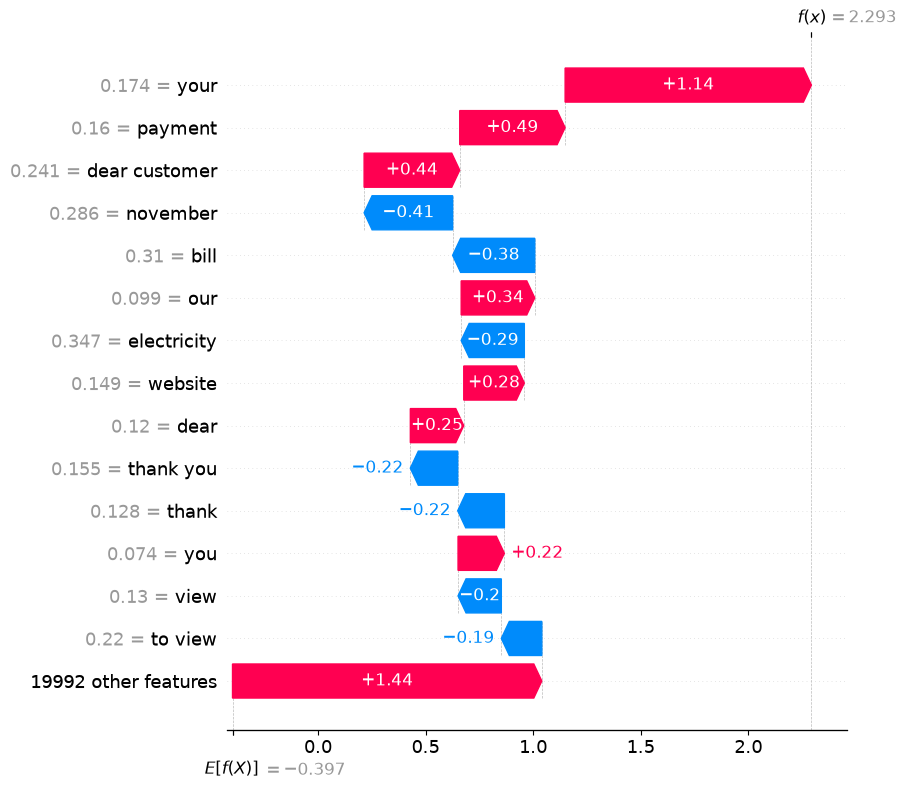

In [62]:

# SHAP EXPLANATION FOR CUSTOM EMAIL

# Get SHAP explanation for the entered email
custom_explanation = explainer(X_custom)

# Attach actual feature names
feature_names = (
    tfidf_vectorizer.get_feature_names_out().tolist()
    + numerical_feature_names
)

custom_explanation.feature_names = feature_names

# Display the waterfall plot
shap.plots.waterfall(
    custom_explanation[0],
    max_display=15
)


In [68]:
# FINAL AUTOMATIC SHAP EXPLANATION

prediction = lr_model.predict(X_custom)[0]
probabilities = lr_model.predict_proba(X_custom)[0]

feature_contributions = [
    (feature_names[i], custom_shap_values[i])
    for i in range(len(feature_names))
]

# Ignore negligible contributions
SHAP_THRESHOLD = 0.01

feature_contributions = [
    (feature, value)
    for feature, value in feature_contributions
    if abs(value) >= SHAP_THRESHOLD
]


if prediction == 1:
    predicted_class = "Spam / Malicious"
    supporting = [x for x in feature_contributions if x[1] > 0]
    opposing = [x for x in feature_contributions if x[1] < 0]
else:
    predicted_class = "Legitimate"
    supporting = [x for x in feature_contributions if x[1] < 0]
    opposing = [x for x in feature_contributions if x[1] > 0]

supporting.sort(key=lambda x: abs(x[1]), reverse=True)
opposing.sort(key=lambda x: abs(x[1]), reverse=True)

def explain_feature(feature):
    f = feature.lower()

    if any(word in f for word in
           ["suspended", "blocked", "locked", "terminated", "deactivated"]):
        return "This language suggests a possible threat or restriction on account access."

    elif any(word in f for word in
             ["account", "bank", "payment", "credit card", "financial"]):
        return "This relates to accounts or financial information."

    elif any(word in f for word in
             ["urgent", "immediately", "expires", "hurry", "limited time"]):
        return "This language may create urgency or pressure the recipient."

    elif any(word in f for word in
             ["verify", "verification", "password", "credentials"]):
        return "This relates to identity verification or sensitive account details."

    elif any(word in f for word in
             ["meeting", "project", "students", "lecture", "assignment"]):
        return "This supports an academic or ordinary work-related context."

    elif any(word in f for word in
             ["report", "scheduled", "friday", "review", "discussion"]):
        return "This is associated with routine communication or scheduled activities."

    else:
        return "This feature contributed to the model's decision based on patterns learned during training."

print("========== EMAIL ANALYSIS ==========")
print("Prediction:", predicted_class)
print(f"Legitimate Probability: {probabilities[0]*100:.2f}%")
print(f"Malicious Probability: {probabilities[1]*100:.2f}%")

print("\nWHY DID THE MODEL REACH THIS CONCLUSION?")

print("\nImportant features supporting the prediction:")

for i, (feature, value) in enumerate(supporting[:5], 1):
    print(f"\n{i}. Feature: '{feature}'")
    print("   Explanation:", explain_feature(feature))
    print(f"   SHAP contribution: {value:.4f}")

print("\nFeatures that opposed the prediction:")

if opposing:
    for i, (feature, value) in enumerate(opposing[:3], 1):
        print(f"{i}. '{feature}' (SHAP: {value:.4f})")
else:
    print("No opposing features.")

print("\nNote: SHAP contributions show how features influenced "
      "the model. The descriptions are explanatory keyword patterns.")

print("====================================")

========== EMAIL ANALYSIS ==========
Prediction: Legitimate
Legitimate Probability: 97.71%
Malicious Probability: 2.29%

WHY DID THE MODEL REACH THIS CONCLUSION?

Important features supporting the prediction:

1. Feature: 'thanks'
   Explanation: This feature contributed to the model's decision based on patterns learned during training.
   SHAP contribution: -0.9385

2. Feature: 'meeting'
   Explanation: This supports an academic or ordinary work-related context.
   SHAP contribution: -0.5013

3. Feature: 'wednesday'
   Explanation: This feature contributed to the model's decision based on patterns learned during training.
   SHAP contribution: -0.4702

4. Feature: 'discuss'
   Explanation: This feature contributed to the model's decision based on patterns learned during training.
   SHAP contribution: -0.4365

5. Feature: 'project'
   Explanation: This supports an academic or ordinary work-related context.
   SHAP contribution: -0.4117

Features that opposed the prediction:
1. 'hello'